# U2P1 | Aplicación de un modelo de Machine Learning de regresión lineal

**Alumno:** Roberto Rodríguez Estrada  
**Número de control:** 22540484  
**Práctica:** Predicción de ventas con el conjunto de datos Big Mart

---

**Enfoque elegido:** comparación de una regresión lineal múltiple con **Elastic Net**, una variante regularizada que combina penalizaciones L1 y L2. Se incorporan exploración visual, limpieza, validación cruzada y análisis de errores.

> Este cuaderno debe ejecutarse con `bigMartSales.csv`. Los resultados de evaluación se calculan al ejecutar el código; no se presentan cifras inventadas.

## 1. Planteamiento del problema

Una cadena comercial necesita estimar las ventas que puede alcanzar un producto en una tienda. Se utilizarán las características de los artículos y de los establecimientos para construir un **modelo de regresión supervisada**.

- **Objetivo (`y`):** `Item_Outlet_Sales`, ventas del producto en una tienda determinada.
- **Predictores (`X`):** atributos del producto y del establecimiento, excluyendo identificadores.
- **Criterios de evaluación:** error absoluto medio (MAE), raíz del error cuadrático medio (RMSE) y coeficiente de determinación (R²).

A diferencia de la regresión lineal sin penalización, **Elastic Net** puede reducir coeficientes de variables poco relevantes. Su desempeño se comparará con un modelo lineal tradicional usando la **misma partición** de datos.

### Diccionario de datos

| Columna | Significado |
|---|---|
| `Item_Identifier` | Identificador del producto |
| `Item_Weight` | Peso del artículo |
| `Item_Fat_Content` | Clasificación del contenido de grasa |
| `Item_Visibility` | Proporción de espacio visible ocupada por el artículo |
| `Item_Type` | Categoría del producto |
| `Item_MRP` | Precio máximo de venta sugerido |
| `Outlet_Identifier` | Identificador de la tienda |
| `Outlet_Establishment_Year` | Año de establecimiento de la tienda |
| `Outlet_Size` | Tamaño del establecimiento |
| `Outlet_Location_Type` | Tipo de ubicación |
| `Outlet_Type` | Tipo de establecimiento |
| `Item_Outlet_Sales` | **Ventas que se pretenden estimar** |

## 2. Bibliotecas y configuración

`pandas` y `numpy` permiten manipular los datos; `matplotlib` y `seaborn` generan visualizaciones; `scikit-learn` se utiliza para preparar los datos, entrenar y evaluar los modelos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
SEMILLA = 42  # Garantiza una partición reproducible
print("Bibliotecas listas. Semilla aleatoria:", SEMILLA)

Bibliotecas listas. Semilla aleatoria: 42


## 3. Carga del conjunto de datos

Se utiliza el archivo original `bigMartSales.csv`, que contiene los **8,523 registros y 12 columnas**. El cuaderno también reconoce `bigMartSales(1).csv`, como se recibió. En Google Colab, al ejecutarse la celda, si el archivo no se encuentra en el entorno se abrirá la ventana para subir el CSV desde el equipo.

**Nota de reproducibilidad:** las gráficas, el entrenamiento y las métricas de este archivo fueron generados con el CSV aportado. Las métricas son específicas de la división y parámetros documentados en el código.

In [2]:
from pathlib import Path

# Rutas comunes en Jupyter y Google Colab. Acepta el nombre original
# del archivo o una copia descargada como "bigMartSales(1).csv".
ubicaciones = [
    Path("bigMartSales.csv"),
    Path("bigMartSales(1).csv"),
    Path("/content/bigMartSales.csv"),
    Path("/content/bigMartSales(1).csv"),
    Path("/content/drive/MyDrive/Colab Notebooks/bigMartSales.csv"),
    Path("/mnt/data/bigMartSales.csv"),
    Path("/mnt/data/bigMartSales(1).csv"),
]
ruta_csv = next((p for p in ubicaciones if p.is_file()), None)

if ruta_csv is None:
    try:
        from google.colab import files
        print("Sube bigMartSales.csv (o bigMartSales(1).csv) desde tu equipo.")
        subidos = files.upload()
        nombres_csv = [nombre for nombre in subidos if nombre.lower().endswith(".csv")]
        if not nombres_csv:
            raise FileNotFoundError("Se requiere el archivo CSV de Big Mart.")
        ruta_csv = Path(nombres_csv[0])
    except ImportError as e:
        raise FileNotFoundError(
            "Coloca el archivo bigMartSales.csv junto al cuaderno y vuelve a ejecutar."
        ) from e

ventas = pd.read_csv(ruta_csv)
columnas_requeridas = {"Item_MRP", "Outlet_Type", "Item_Outlet_Sales", "Item_Fat_Content", "Outlet_Establishment_Year"}
if not columnas_requeridas.issubset(ventas.columns):
    raise ValueError("El CSV no corresponde a Big Mart: faltan columnas obligatorias.")
print(f"Archivo leído: {ruta_csv}")
print(f"Registros: {ventas.shape[0]:,} | Columnas: {ventas.shape[1]}")
display(ventas.head())

Archivo leído: bigMartSales.csv
Registros: 8,523 | Columnas: 12


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 4. Exploración inicial

Antes de crear el modelo se inspeccionan los tipos de datos, la presencia de registros duplicados y los valores faltantes. Esta revisión permite decidir qué transformaciones son necesarias sin modificar aún el conjunto original.

In [3]:
print("--- INFORMACIÓN GENERAL ---")
ventas.info()
print("\nRegistros duplicados completos:", ventas.duplicated().sum())
print("\nNúmero de categorías/valores por columna:")
display(ventas.nunique(dropna=True).to_frame("Valores únicos"))

--- INFORMACIÓN GENERAL ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB

Registros duplic

,Valores únicos
Item_Identifier,1559
Item_Weight,415
Item_Fat_Content,5
Item_Visibility,7880
Item_Type,16
Item_MRP,5938
Outlet_Identifier,10
Outlet_Establishment_Year,9
Outlet_Size,3
Outlet_Location_Type,3


,Tipo,Nulos,Porcentaje de nulos
Outlet_Size,object,2410,28.28
Item_Weight,float64,1463,17.17
Item_Fat_Content,object,0,0.00
Item_Identifier,object,0,0.00
Item_Visibility,float64,0,0.00
Item_Type,object,0,0.00
Outlet_Identifier,object,0,0.00
Item_MRP,float64,0,0.00
Outlet_Establishment_Year,int64,0,0.00
Outlet_Location_Type,object,0,0.00


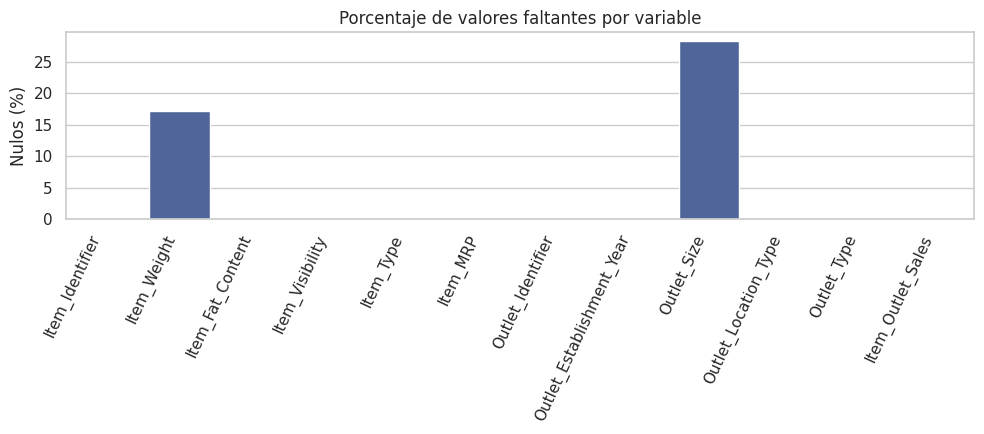

In [4]:
resumen = pd.DataFrame({
    "Tipo": ventas.dtypes.astype(str),
    "Nulos": ventas.isna().sum(),
    "Porcentaje de nulos": (ventas.isna().mean() * 100).round(2),
})
display(resumen.sort_values("Porcentaje de nulos", ascending=False))

plt.figure(figsize=(10, 4.5))
sns.barplot(x=resumen.index, y=resumen["Porcentaje de nulos"], color="#4361a8")
plt.title("Porcentaje de valores faltantes por variable")
plt.ylabel("Nulos (%)")
plt.xlabel("")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

### 4.1. Estadística descriptiva

La media, mediana y dispersión permiten conocer las escalas y posibles valores extremos. También es importante revisar las frecuencias de las variables cualitativas.

In [5]:
display(ventas.describe().T.round(2))
display(ventas.describe(include=["object", "category"]).T)
for columna in ["Item_Fat_Content", "Outlet_Size", "Outlet_Type"]:
    if columna in ventas.columns:
        print(f"\n{columna}:")
        display(ventas[columna].value_counts(dropna=False).to_frame("Frecuencia"))

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.86,4.64,4.56,8.77,12.60,16.85,21.35
Item_Visibility,8523.0,0.07,0.05,0.00,0.03,0.05,0.09,0.33
Item_MRP,8523.0,140.99,62.28,31.29,93.83,143.01,185.64,266.89
Outlet_Establishment_Year,8523.0,1997.83,8.37,1985.00,1987.00,1999.00,2004.00,2009.00
Item_Outlet_Sales,8523.0,2181.29,1706.50,33.29,834.25,1794.33,3101.30,13086.96


,count,unique,top,freq
Item_Identifier,8523,1559,FDW13,10
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Identifier,8523,10,OUT027,935
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577



Item_Fat_Content:


,Frecuencia
Item_Fat_Content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112



Outlet_Size:


,Frecuencia
Outlet_Size,
Medium,2793
NaN,2410
Small,2388
High,932



Outlet_Type:


,Frecuencia
Outlet_Type,
Supermarket Type1,5577
Grocery Store,1083
Supermarket Type3,935
Supermarket Type2,928


### 4.2. Visualización de ventas y sus posibles relaciones

Se revisa la distribución de la variable objetivo y su relación con el precio de venta sugerido. La comparación por tipo de tienda permite explorar si existen diferencias visibles entre establecimientos.

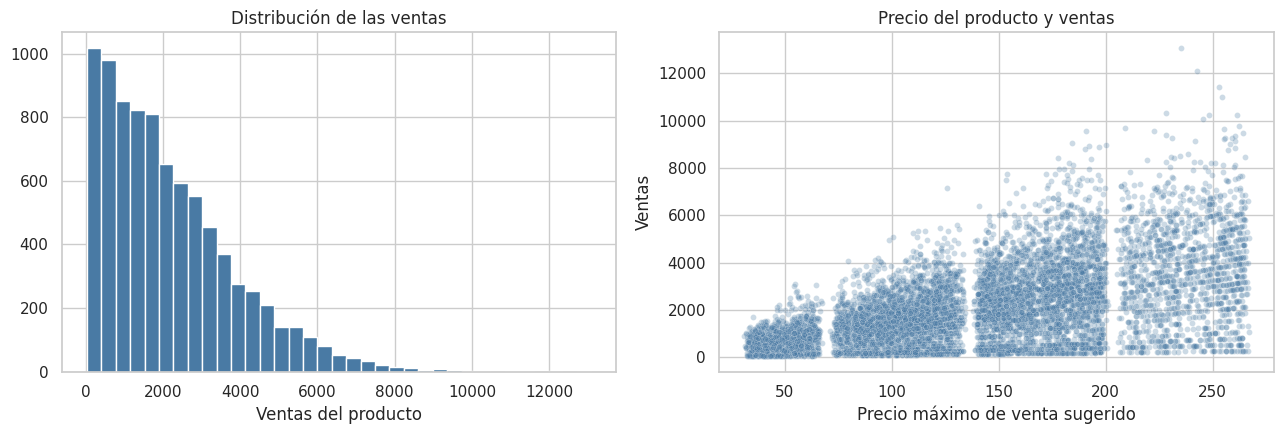

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].hist(ventas["Item_Outlet_Sales"].dropna(), bins=35, color="#497aa4", edgecolor="white")
ejes[0].set_title("Distribución de las ventas")
ejes[0].set_xlabel("Ventas del producto")
sns.scatterplot(data=ventas, x="Item_MRP", y="Item_Outlet_Sales",
                color="#497aa4", alpha=0.28, s=18, ax=ejes[1])
ejes[1].set_title("Precio del producto y ventas")
ejes[1].set_xlabel("Precio máximo de venta sugerido")
ejes[1].set_ylabel("Ventas")
plt.tight_layout()
plt.show()

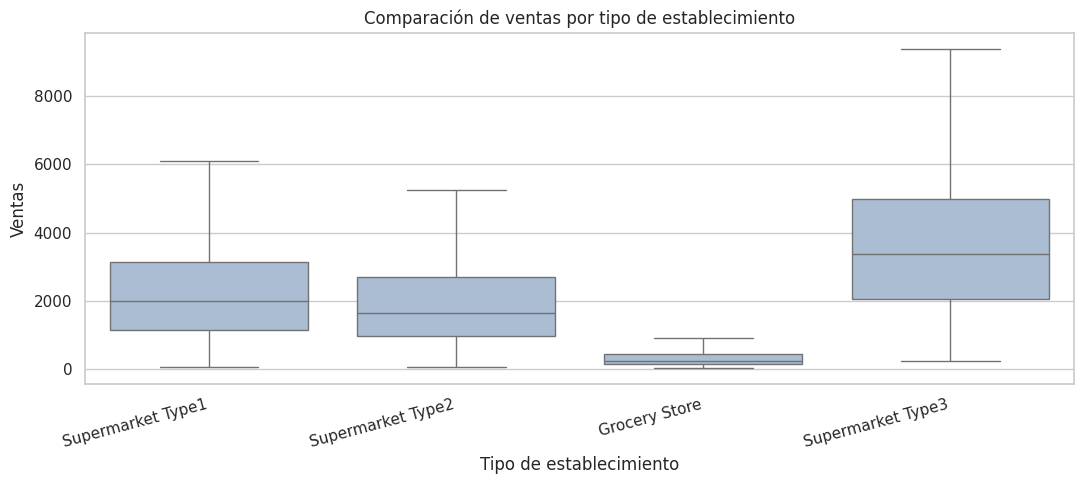

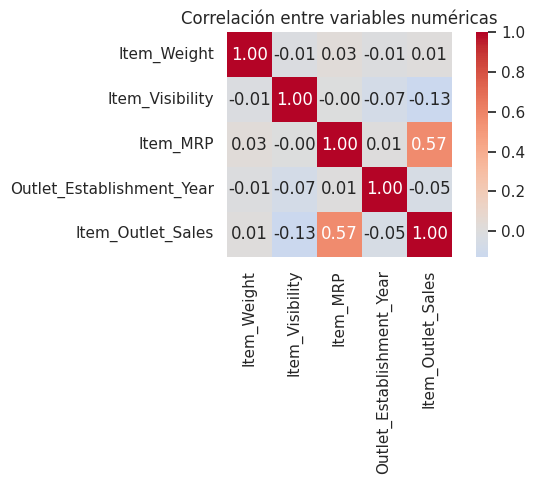

In [7]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=ventas, x="Outlet_Type", y="Item_Outlet_Sales",
            color="#a5bdd8", showfliers=False)
plt.title("Comparación de ventas por tipo de establecimiento")
plt.xlabel("Tipo de establecimiento")
plt.ylabel("Ventas")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

columnas_numericas = ventas.select_dtypes(include="number")
plt.figure(figsize=(7, 5))
sns.heatmap(columnas_numericas.corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", square=True)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

## 5. Limpieza e ingeniería de características

Se trabaja con una copia de los datos para conservar la información original. Se aplican tres decisiones:

1. Normalizar etiquetas equivalentes de contenido de grasa (`LF`, `low fat` y `Low Fat`, entre otras).
2. Transformar el año de apertura a la variable **`Outlet_Age`** (antigüedad de la tienda) usando un año de referencia fijo, para que los resultados sean reproducibles.
3. Excluir identificadores de producto y tienda, como en los ejemplos de esta práctica.

**Importante:** los valores faltantes en los predictores se imputarán dentro de los *pipelines* y **después** de separar entrenamiento y prueba, lo que evita utilizar información del conjunto de prueba durante el ajuste.

In [8]:
datos = ventas.copy().drop_duplicates()

# La variable objetivo no debe imputarse: se retiran solo sus registros nulos.
datos = datos.dropna(subset=["Item_Outlet_Sales"])

def estandarizar_grasa(valor):
    if pd.isna(valor):
        return np.nan
    equivalencias = {
        "lf": "Low Fat", "low fat": "Low Fat",
        "regular": "Regular", "reg": "Regular"
    }
    return equivalencias.get(str(valor).strip().lower(), str(valor).strip())

datos["Item_Fat_Content"] = datos["Item_Fat_Content"].map(estandarizar_grasa)

ANIO_REFERENCIA = 2026
datos["Outlet_Age"] = ANIO_REFERENCIA - datos["Outlet_Establishment_Year"]
datos = datos.drop(columns=["Outlet_Establishment_Year", "Item_Identifier", "Outlet_Identifier"])

print("Categorías unificadas de grasa:")
print(datos["Item_Fat_Content"].value_counts(dropna=False))
print("\nDimensiones tras la limpieza:", datos.shape)
display(datos.head())

Categorías unificadas de grasa:
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Dimensiones tras la limpieza: (8523, 10)


,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Outlet_Age
0,9.30,Low Fat,0.016047,Dairy,249.8092,Medium,Tier 1,Supermarket Type1,3735.1380,27
1,5.92,Regular,0.019278,Soft Drinks,48.2692,Medium,Tier 3,Supermarket Type2,443.4228,17
2,17.50,Low Fat,0.016760,Meat,141.6180,Medium,Tier 1,Supermarket Type1,2097.2700,27
3,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,NaN,Tier 3,Grocery Store,732.3800,28
4,8.93,Low Fat,0.000000,Household,53.8614,High,Tier 3,Supermarket Type1,994.7052,39


## 6. Variables de entrada y partición de datos

`X` agrupa las características con las cuales se intentará predecir. `y` contiene `Item_Outlet_Sales`. Se reserva el **20%** para evaluación final y el **80%** para entrenamiento. Se utiliza la misma separación en ambos modelos para que la comparación sea justa.

In [9]:
X = datos.drop(columns="Item_Outlet_Sales")
y = datos["Item_Outlet_Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

columnas_num = X.select_dtypes(include="number").columns.tolist()
columnas_cat = X.select_dtypes(exclude="number").columns.tolist()

print(f"Entrenamiento: {len(X_train):,} registros")
print(f"Prueba: {len(X_test):,} registros")
print("Variables numéricas:", columnas_num)
print("Variables categóricas:", columnas_cat)

Entrenamiento: 6,818 registros
Prueba: 1,705 registros
Variables numéricas: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age']
Variables categóricas: ['Item_Fat_Content', 'Item_Type', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


## 7. Procesamiento mediante *pipeline*

Las variables numéricas requieren una escala comparable para regularizar correctamente. Por ello se usa **`StandardScaler`** en lugar de MinMaxScaler. Para los valores faltantes se utiliza la mediana (numéricos) o la categoría más frecuente (categóricos). Finalmente, **`OneHotEncoder`** convierte las categorías a columnas binarias.

El *pipeline* aplica exactamente las transformaciones aprendidas en entrenamiento cuando se predicen datos nuevos.

In [10]:
# Compatible con versiones recientes y anteriores de scikit-learn.
try:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse=False)

numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])
categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", codificador)
])

preprocesamiento = ColumnTransformer(transformers=[
    ("num", numerico, columnas_num),
    ("cat", categorico, columnas_cat)
])
print("Pipeline de transformación configurado.")

Pipeline de transformación configurado.


## 8. Modelo de referencia: regresión lineal múltiple

Primero se entrena una regresión lineal ordinaria. Este modelo actúa como **línea base** y permitirá juzgar si agregar regularización ofrece una mejora real.

In [11]:
modelo_lineal = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("regresion", LinearRegression())
])
modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)
print("Regresión lineal entrenada correctamente.")

Regresión lineal entrenada correctamente.


## 9. Propuesta diferente: regresión Elastic Net

**Elastic Net** conserva el enfoque de regresión lineal, pero incorpora dos tipos de penalización:

- **L1 (Lasso):** puede llevar algunos coeficientes a cero y ayudar a seleccionar variables.
- **L2 (Ridge):** reduce coeficientes grandes y estabiliza el ajuste.

Los parámetros `alpha` (intensidad de la penalización) y `l1_ratio` (proporción relativa entre L1 y L2) se buscarán con **`GridSearchCV` y validación cruzada de 3 particiones**. La selección se realiza exclusivamente con el conjunto de entrenamiento; así el 20% de prueba permanece sin utilizar hasta el final.

In [12]:
modelo_elastic = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("regresion", ElasticNet(max_iter=20000, random_state=SEMILLA))
])

parametros = {
    "regresion__alpha": [0.1, 1.0, 10.0, 100.0],
    "regresion__l1_ratio": [0.25, 0.5, 0.8, 1.0]
}

busqueda = GridSearchCV(
    estimator=modelo_elastic,
    param_grid=parametros,
    scoring="neg_mean_squared_error",   # Al minimizar MSE, también minimizamos RMSE.
    cv=KFold(n_splits=3, shuffle=True, random_state=SEMILLA),
    n_jobs=1,  # Evita saturar los recursos gratuitos de Colab.
    refit=True
)
busqueda.fit(X_train, y_train)
mejor_elastic = busqueda.best_estimator_
pred_elastic = mejor_elastic.predict(X_test)

print("Mejores parámetros:", busqueda.best_params_)
print(f"RMSE promedio en validación cruzada: {np.sqrt(-busqueda.best_score_):,.2f}")

Mejores parámetros: {'regresion__alpha': 1.0, 'regresion__l1_ratio': 1.0}
RMSE promedio en validación cruzada: 1,146.62


## 10. Evaluación objetiva de ambos modelos

Se calculan métricas sobre los **mismos registros de prueba**. Un MAE o RMSE menor indica menor error; un R² mayor indica mayor capacidad explicativa con respecto a predecir la media.

No se presupone que Elastic Net sea superior: la comparación debe basarse en los resultados obtenidos al ejecutar el cuaderno.

In [13]:
def evaluar(nombre, reales, estimadas):
    return {
        "Modelo": nombre,
        "MAE": mean_absolute_error(reales, estimadas),
        "RMSE": np.sqrt(mean_squared_error(reales, estimadas)),
        "R²": r2_score(reales, estimadas)
    }

resultados = pd.DataFrame([
    evaluar("Regresión lineal", y_test, pred_lineal),
    evaluar("Elastic Net", y_test, pred_elastic)
]).set_index("Modelo")

display(resultados.round(3))
mejor_rmse = resultados["RMSE"].idxmin()
print(f"Menor RMSE en este conjunto de prueba: {mejor_rmse}")
print("Nota: la elección de hiperparámetros se hizo por validación cruzada, no por estos datos de prueba.")

,MAE,RMSE,R²
Modelo,,,
Regresión lineal,791.596,1068.944,0.580
Elastic Net,792.059,1069.969,0.579


Menor RMSE en este conjunto de prueba: Regresión lineal
Nota: la elección de hiperparámetros se hizo por validación cruzada, no por estos datos de prueba.


### 10.1. Ventas reales frente a ventas estimadas

Una predicción ideal se ubicaría sobre la diagonal punteada. Cuanto mayor sea la dispersión respecto de esa línea, mayor será el error.

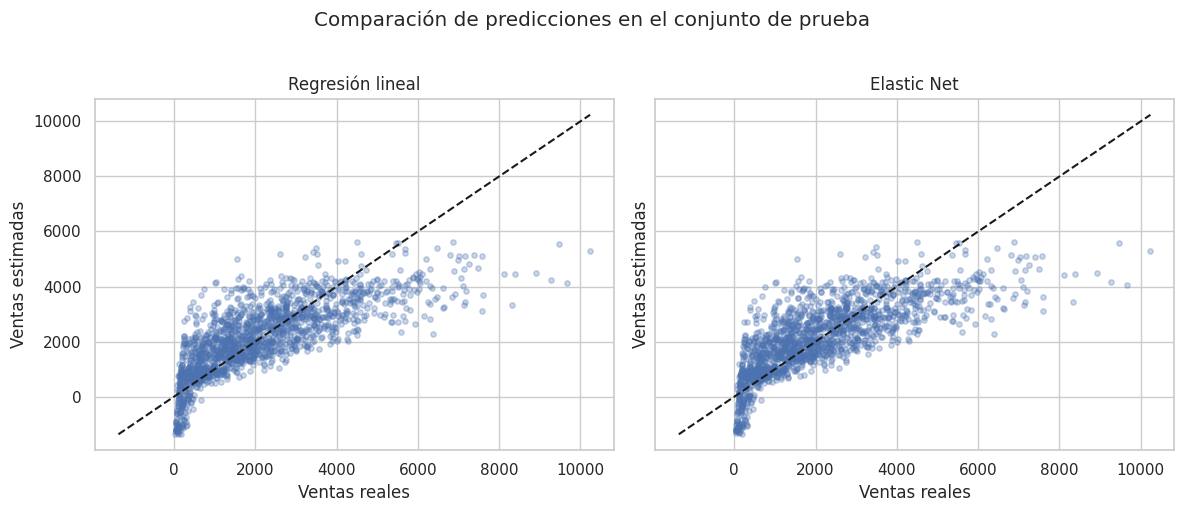

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
limite_min = min(float(y_test.min()), float(pred_lineal.min()), float(pred_elastic.min()))
limite_max = max(float(y_test.max()), float(pred_lineal.max()), float(pred_elastic.max()))
for ax, estimadas, titulo in zip(
    ejes, [pred_lineal, pred_elastic], ["Regresión lineal", "Elastic Net"]
):
    ax.scatter(y_test, estimadas, alpha=0.3, s=15)
    ax.plot([limite_min, limite_max], [limite_min, limite_max], "k--", linewidth=1.5)
    ax.set_title(titulo)
    ax.set_xlabel("Ventas reales")
    ax.set_ylabel("Ventas estimadas")
plt.suptitle("Comparación de predicciones en el conjunto de prueba", y=1.02)
plt.tight_layout()
plt.show()

### 10.2. Análisis de los residuos de Elastic Net

El **residuo** es la diferencia entre la venta real y la predicción. Su gráfico permite observar si los errores mantienen algún patrón que el modelo lineal no logra explicar.

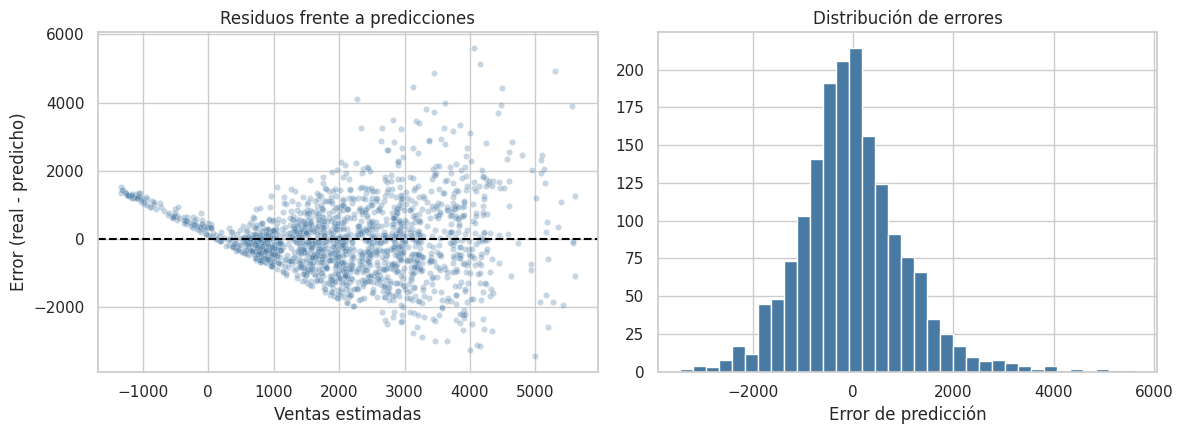

In [15]:
residuos = y_test.to_numpy() - pred_elastic
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=pred_elastic, y=residuos, color="#497aa4", alpha=0.3, s=20, ax=ejes[0])
ejes[0].axhline(0, color="black", linestyle="--")
ejes[0].set_title("Residuos frente a predicciones")
ejes[0].set_xlabel("Ventas estimadas")
ejes[0].set_ylabel("Error (real - predicho)")
ejes[1].hist(residuos, bins=35, color="#497aa4", edgecolor="white")
ejes[1].set_title("Distribución de errores")
ejes[1].set_xlabel("Error de predicción")
plt.tight_layout()
plt.show()

## 11. Interpretación de los coeficientes

En Elastic Net, cada coeficiente representa el efecto lineal estimado de una característica **manteniendo constantes las demás**. Los coeficientes numéricos corresponden a variables estandarizadas; los categóricos a indicadores 0/1. Por tanto, sus magnitudes no deben interpretarse como causalidad ni compararse sin contexto.

Número de coeficientes: 32
Coeficientes con valor cercano a cero: 15


,Variable,Coeficiente
28,cat__Outlet_Type_Grocery Store,-1924.791
31,cat__Outlet_Type_Supermarket Type3,1427.557
2,num__Item_MRP,977.965
30,cat__Outlet_Type_Supermarket Type2,-320.923
18,cat__Item_Type_Seafood,85.388
10,cat__Item_Type_Dairy,-73.277
4,cat__Item_Fat_Content_Low Fat,-45.506
12,cat__Item_Type_Fruits and Vegetables,40.043
22,cat__Outlet_Size_High,28.193
23,cat__Outlet_Size_Medium,-23.989


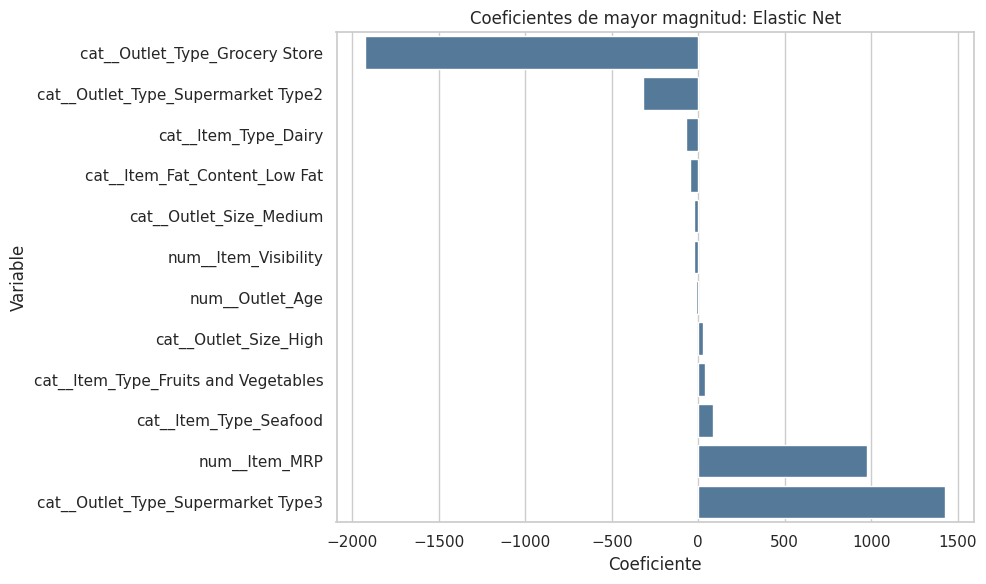

In [16]:
variables_modelo = mejor_elastic.named_steps["preprocesamiento"].get_feature_names_out()
coeficientes = mejor_elastic.named_steps["regresion"].coef_
tabla_coef = pd.DataFrame({
    "Variable": variables_modelo,
    "Coeficiente": coeficientes,
    "Magnitud": np.abs(coeficientes)
}).sort_values("Magnitud", ascending=False)

print("Número de coeficientes:", len(tabla_coef))
print("Coeficientes con valor cercano a cero:",
      int(np.isclose(tabla_coef["Coeficiente"], 0.0, atol=1e-6).sum()))
display(tabla_coef.head(12).drop(columns="Magnitud").round(3))

principales = tabla_coef.head(12).sort_values("Coeficiente")
plt.figure(figsize=(10, 6))
sns.barplot(data=principales, x="Coeficiente", y="Variable", color="#497aa4")
plt.title("Coeficientes de mayor magnitud: Elastic Net")
plt.tight_layout()
plt.show()

## 12. Ejemplo de predicciones

Se muestran diez observaciones del conjunto de prueba, sin inventar datos nuevos. Esto ayuda a apreciar la magnitud de los errores caso por caso.

In [17]:
comparacion = pd.DataFrame({
    "Venta real": y_test.to_numpy(),
    "Predicción lineal": pred_lineal,
    "Predicción Elastic Net": pred_elastic,
    "Error absoluto Elastic Net": np.abs(y_test.to_numpy() - pred_elastic)
})
display(comparacion.head(10).round(2))

,Venta real,Predicción lineal,Predicción Elastic Net,Error absoluto Elastic Net
0,1743.06,1359.06,1360.93,382.14
1,356.87,762.01,765.77,408.90
2,377.51,820.05,798.85,421.34
3,5778.48,4228.87,4238.71,1539.76
4,2356.93,3292.56,3273.22,916.28
5,865.54,579.17,589.02,276.52
6,4613.99,4754.11,4730.11,116.11
7,2410.86,2048.97,2063.68,347.18
8,1948.13,1392.08,1400.45,547.68
9,1937.48,2785.24,2800.06,862.58


## 13. Conclusiones y reflexión

**Interpretación automatizada de los resultados:** la siguiente celda genera un resumen usando las métricas reales. Es necesario ejecutar previamente las celdas anteriores.

In [18]:
a = resultados.loc["Regresión lineal"]
b = resultados.loc["Elastic Net"]
diferencia = a["RMSE"] - b["RMSE"]

print("CONCLUSIONES")
print(f"1. La regresión lineal obtuvo RMSE={a['RMSE']:.2f} y R²={a['R²']:.4f}.")
print(f"2. Elastic Net obtuvo RMSE={b['RMSE']:.2f} y R²={b['R²']:.4f}.")
if diferencia > 0:
    print(f"3. Elastic Net redujo el RMSE en {diferencia:.2f} unidades frente a la línea base.")
elif diferencia < 0:
    print(f"3. La regresión lineal obtuvo un RMSE inferior por {-diferencia:.2f} unidades.")
else:
    print("3. Los dos modelos obtuvieron el mismo RMSE en la prueba.")
print("4. El modelo puede mejorarse evaluando variables adicionales, otras transformaciones y nuevos datos.")
print("5. Las métricas describen desempeño predictivo, no relaciones de causa y efecto.")

CONCLUSIONES
1. La regresión lineal obtuvo RMSE=1068.94 y R²=0.5796.
2. Elastic Net obtuvo RMSE=1069.97 y R²=0.5788.
3. La regresión lineal obtuvo un RMSE inferior por 1.02 unidades.
4. El modelo puede mejorarse evaluando variables adicionales, otras transformaciones y nuevos datos.
5. Las métricas describen desempeño predictivo, no relaciones de causa y efecto.


### Reflexión final

La regresión lineal es un punto de partida para estudiar cómo se relacionan las características de productos y tiendas con sus ventas. Elastic Net introduce un método de regularización distinto, con el propósito de controlar la complejidad de los coeficientes. La comparación se realizó sobre la misma muestra de prueba y la búsqueda de hiperparámetros se limitó al entrenamiento.

Este ejercicio muestra que **agregar complejidad no garantiza mejores predicciones**: conviene comparar modelos con métricas verificables, analizar sus errores y justificar cada decisión de procesamiento.

**Alumno:** Roberto Rodríguez Estrada — **No. de control:** 22540484